# TP2 - MLP en TNG

A partir de la notebook de Regresión Softmax en TNG, entrenar un modelo de MLP cuya búsqueda de  hiperparámetros debe incluir al menos:



Distintas funciones de activación
Distintas cantidades de capas ocultas ( 1, 2 o 3, no más que eso)
Distintas cantidades de neuronas por capa.
Distintos optimizadores con distintos parámetros: Adam, RMSProp, SGD, momentos de orden 1 y 2.
Se deben incluir también los HP buscados en el TP anterior (learning rate, etc).


Además encontrar una cantidad de unidades ocultas y capas de forma tal que el problema quede overfiteado.

Analizar lo encontrado a lo ancho de todos los entrenamientos, comparar performances y tiempos de entrenamiento.



Bonus (y recomiendo que lo prueben para ahorrarse tiempo de entrenamiento): utilizar pruning en optuna.

Bonus recomendado: comparar los resultados con los obtenidos con regresión softmax.

## 0. Setup

In [ ]:
!pip install -q optuna


In [ ]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [ ]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [ ]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [ ]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # Filtrado de Stop Words
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # Normalización (Stemming / Lemmatization)
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

In [ ]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


In [ ]:
# Generación de la caché de preprocesamiento para Optuna
print("Precalculando combinaciones de preprocesamiento (esto puede tardar)...")
preprocessed_cache = {}

norm_options = ["none", "stem", "lemmatize"]
sw_options = [False, True]

for norm in norm_options:
    for sw in sw_options:
        print(f"Procesando: remove_stopwords={sw}, normalization={norm}...")
        train_clean = [preprocess_text(doc, remove_stopwords=sw, normalization=norm) for doc in newsgroups_train.data]
        test_clean  = [preprocess_text(doc, remove_stopwords=sw, normalization=norm) for doc in newsgroups_test.data]
        preprocessed_cache[(sw, norm)] = (train_clean, test_clean)

print("¡Caché de textos lista para usar!")

Precalculando combinaciones de preprocesamiento (esto puede tardar)...
Procesando: remove_stopwords=False, normalization=none...
Procesando: remove_stopwords=True, normalization=none...
Procesando: remove_stopwords=False, normalization=stem...
Procesando: remove_stopwords=True, normalization=stem...
Procesando: remove_stopwords=False, normalization=lemmatize...
Procesando: remove_stopwords=True, normalization=lemmatize...
¡Caché de textos lista para usar!


## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

def vectorize_data(train_texts, test_texts, ngram_range=(1, 1), max_features=5000, min_df=2):
    """
    Convierte textos preprocesados en matrices numéricas TF-IDF.
    stop_words=None porque el filtrado de stopwords ya lo controla preprocess_text.
    """
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df,
        stop_words=None
    )

    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)

    return X_train, X_test, vectorizer

In [ ]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [ ]:
import torch
import torch.nn as nn

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(SoftmaxRegression, self).__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)

class DynamicMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes, activation_name="relu"):
        """
        hidden_dims: lista con las neuronas por capa, ej: [256, 128]
        activation_name: 'relu', 'gelu', 'tanh', 'leaky_relu'
        """
        super(DynamicMLP, self).__init__()

        activations = {
            "relu": nn.ReLU(),
            "gelu": nn.GELU(),
            "tanh": nn.Tanh(),
            "leaky_relu": nn.LeakyReLU()
        }
        act_layer = activations.get(activation_name.lower(), nn.ReLU())

        layers = []
        prev_dim = input_dim

        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(act_layer)
            prev_dim = h_dim

        layers.append(nn.Linear(prev_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [ ]:
%load_ext tensorboard


In [ ]:
import time

def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_mlp_model(model, train_loader, val_loader, optimizer, epochs, trial=None, run_name="mlp", verbose=False, eval_label="Val"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_times": [], "epochs_ran": 0}

    t0_total = time.time()

    for epoch in range(epochs):
        t0_ep = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)

        val_loss = running_loss / total
        val_acc = correct / total
        ep_time = time.time() - t0_ep

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_times"].append(ep_time)
        history["epochs_ran"] = epoch + 1

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1:2d}/{epochs} ({ep_time:.2f}s) - "
                  f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"{eval_label.lower()}_loss: {val_loss:.4f} {eval_label.lower()}_acc: {val_acc:.4f}")

        if trial is not None:
            trial.set_user_attr("epochs_ran", epoch + 1)
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

    history["total_time"] = time.time() - t0_total
    return history

## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

In [ ]:
import pandas as pd

MAX_EPOCHS_OPTUNA = 8
N_TRIALS_MLP = 24

def objective_mlp(trial):
    t0_trial = time.time()
    # 1. Hiperparámetros de NLP
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # 2. Arquitectura del MLP
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_dims = []
    for i in range(n_layers):
        neurons = trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512])
        hidden_dims.append(neurons)

    activation = trial.suggest_categorical("activation", ["relu", "gelu", "tanh", "leaky_relu"])

    # 3. Selección y configuración del Optimizador (con rango de lr acorde a cada tipo)
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])

    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED, stratify=newsgroups_train.target
    )
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)

    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    torch.manual_seed(SEED)
    model = DynamicMLP(input_dim=X_tr.shape[1], hidden_dims=hidden_dims, num_classes=NUM_CLASSES, activation_name=activation)
    trial.set_user_attr("n_params", count_parameters(model))
    trial.set_user_attr("epochs_ran", 0)

    if opt_name == "adam":
        lr = trial.suggest_float("lr_adam", 1e-4, 2e-2, log=True)
        beta1 = trial.suggest_float("adam_beta1", 0.8, 0.99)
        beta2 = trial.suggest_float("adam_beta2", 0.9, 0.9999)
        optimizer = optim.Adam(model.parameters(), lr=lr, betas=(beta1, beta2))
    elif opt_name == "rmsprop":
        lr = trial.suggest_float("lr_rmsprop", 1e-4, 2e-2, log=True)
        alpha = trial.suggest_float("rmsprop_alpha", 0.8, 0.99)
        momentum = trial.suggest_float("rmsprop_momentum", 0.0, 0.9)
        optimizer = optim.RMSprop(model.parameters(), lr=lr, alpha=alpha, momentum=momentum)
    else:  # sgd requiere lr mayor que los métodos adaptativos
        lr = trial.suggest_float("lr_sgd", 5e-2, 1.0, log=True)
        momentum = trial.suggest_float("sgd_momentum", 0.5, 0.95)
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    try:
        history = train_mlp_model(model, train_loader, val_loader, optimizer, epochs=MAX_EPOCHS_OPTUNA, trial=trial, run_name=f"trial_{trial.number}", verbose=False)
        trial.set_user_attr("duration_sec", round(time.time() - t0_trial, 2))
        return history["val_acc"][-1]
    except optuna.exceptions.TrialPruned:
        trial.set_user_attr("duration_sec", round(time.time() - t0_trial, 2))
        raise

# Pruner moderado: deja 6 trials completos de referencia y espera 4 épocas antes de podar
pruner = optuna.pruners.MedianPruner(n_startup_trials=6, n_warmup_steps=4)
study_mlp = optuna.create_study(direction="maximize", pruner=pruner, sampler=optuna.samplers.TPESampler(seed=SEED))

start_time = time.time()
study_mlp.optimize(objective_mlp, n_trials=N_TRIALS_MLP)
mlp_optuna_time = time.time() - start_time

# Cuantificación del ahorro del Pruning
df_mlp = study_mlp.trials_dataframe(attrs=("number", "state", "value", "params", "user_attrs"))
completed_df = df_mlp[df_mlp["state"] == "COMPLETE"].copy()
pruned_df = df_mlp[df_mlp["state"] == "PRUNED"].copy()

epochs_ran_total = int(df_mlp["user_attrs_epochs_ran"].fillna(0).sum())
epochs_without_pruning = N_TRIALS_MLP * MAX_EPOCHS_OPTUNA
epochs_saved = epochs_without_pruning - epochs_ran_total
avg_sec_per_epoch = df_mlp["user_attrs_duration_sec"].sum() / max(epochs_ran_total, 1)
est_time_saved = epochs_saved * avg_sec_per_epoch

print(f"\nTiempo total búsqueda Optuna MLP: {mlp_optuna_time:.2f}s")
print(f"Trials totales: {N_TRIALS_MLP} | Completados: {len(completed_df)} | Podados (Pruned): {len(pruned_df)}")
print(f"Épocas ejecutadas: {epochs_ran_total} / {epochs_without_pruning} "
      f"(Ahorro por pruning: {epochs_saved} épocas [{100*epochs_saved/epochs_without_pruning:.1f}%], ~{est_time_saved:.1f}s estimados)")
print("Mejores hiperparámetros encontrados:", study_mlp.best_params)
print(f"Mejor accuracy de validación: {study_mlp.best_value:.4f}")

print("\n--- Resumen por Función de Activación (Trials Completados) ---")
display(completed_df.groupby("params_activation").agg(
    trials_completados=("value", "count"),
    val_acc_media=("value", "mean"),
    val_acc_max=("value", "max"),
    duracion_media_s=("user_attrs_duration_sec", "mean")
).round(4))

print("\n--- Resumen por Optimizador (Trials Completados) ---")
display(completed_df.groupby("params_optimizer").agg(
    trials_completados=("value", "count"),
    val_acc_media=("value", "mean"),
    val_acc_max=("value", "max"),
    duracion_media_s=("user_attrs_duration_sec", "mean")
).round(4))

print("\n--- Resumen por Cantidad de Capas Ocultas (Trials Completados) ---")
display(completed_df.groupby("params_n_layers").agg(
    trials_completados=("value", "count"),
    val_acc_media=("value", "mean"),
    val_acc_max=("value", "max"),
    params_medios=("user_attrs_n_params", "mean")
).round(4))

display(df_mlp.sort_values(by="value", ascending=False).reset_index(drop=True))

[I 2026-11-19 16:54:19,644] A new study created in memory with name: no-name-11059a28-4369-431c-964b-3e1caaddfd25
[I 2026-11-19 16:54:53,801] Trial 0 finished with value: 0.5992045956694653 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'batch_size': 32, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'leaky_relu', 'optimizer': 'adam', 'lr_adam': 0.002307616804011732, 'adam_beta1': 0.8088255784167996, 'adam_beta2': 0.9606937307049537}. Best is trial 0 with value: 0.5992045956694653.
[I 2026-11-19 16:55:03,362] Trial 1 finished with value: 0.3932832523199293 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 5, 'batch_size': 64, 'n_layers': 2, 'n_units_l0': 256, 'n_units_l1': 64, 'activation': 'leaky_relu', 'optimizer': 'sgd', 'lr_sgd': 0.14558505116213707, 'sgd_momentum': 0.6264205293593214}. Best is trial 0 with value: 0.599204595669


Tiempo total búsqueda Optuna MLP: 717.18s
Trials totales: 24 | Completados: 17 | Podados (Pruned): 7
Épocas ejecutadas: 171 / 192 (Ahorro por pruning: 21 épocas [10.9%], ~88.0s estimados)
Mejores hiperparámetros encontrados: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'batch_size': 128, 'n_layers': 2, 'n_units_l0': 512, 'n_units_l1': 512, 'activation': 'leaky_relu', 'optimizer': 'adam', 'lr_adam': 0.00038642204017717163, 'adam_beta1': 0.8539599140745215, 'adam_beta2': 0.9293853452102516}
Mejor accuracy de validación: 0.7300

--- Resumen por Función de Activación (Trials Completados) ---


,trials_completados,val_acc_media,val_acc_max,duracion_media_s
params_activation,,,,
gelu,1,0.6412,0.6412,6.4400
leaky_relu,3,0.5742,0.7300,41.0967
relu,5,0.6225,0.7203,60.9560
tanh,8,0.6615,0.7167,25.5550



--- Resumen por Optimizador (Trials Completados) ---


,trials_completados,val_acc_media,val_acc_max,duracion_media_s
params_optimizer,,,,
adam,11,0.6493,0.7300,42.2145
rmsprop,5,0.6464,0.6995,33.0080
sgd,1,0.3933,0.3933,9.5500



--- Resumen por Cantidad de Capas Ocultas (Trials Completados) ---


,trials_completados,val_acc_media,val_acc_max,params_medios
params_n_layers,,,,
1,5,0.6338,0.6571,6.459336e+05
2,9,0.6620,0.7300,3.730473e+06
3,3,0.5472,0.6425,3.416307e+05


,number,state,value,params_activation,params_adam_beta1,params_adam_beta2,params_batch_size,params_lr_adam,params_lr_rmsprop,params_lr_sgd,...,params_ngram_range,params_normalization,params_optimizer,params_remove_stopwords,params_rmsprop_alpha,params_rmsprop_momentum,params_sgd_momentum,user_attrs_duration_sec,user_attrs_epochs_ran,user_attrs_n_params
0,21,COMPLETE,0.730004,leaky_relu,0.853960,0.929385,128,0.000386,NaN,NaN,...,1gram,stem,adam,False,NaN,NaN,NaN,79.60,8,5393428
1,18,COMPLETE,0.720283,relu,0.843754,0.922907,128,0.000513,NaN,NaN,...,1gram,stem,adam,False,NaN,NaN,NaN,71.36,8,5393428
2,19,COMPLETE,0.716748,tanh,0.853372,0.928069,128,0.000531,NaN,NaN,...,1gram,stem,adam,False,NaN,NaN,NaN,68.85,8,5393428
3,17,COMPLETE,0.714096,tanh,0.854018,0.928535,128,0.000597,NaN,NaN,...,1gram,stem,adam,False,NaN,NaN,NaN,69.20,8,5393428
4,23,COMPLETE,0.699514,relu,NaN,NaN,128,NaN,0.019938,NaN,...,1gram,stem,rmsprop,True,0.861789,0.100909,NaN,128.47,8,5393428
5,22,COMPLETE,0.693769,relu,0.845767,0.925696,128,0.000282,NaN,NaN,...,1gram,none,adam,False,NaN,NaN,NaN,72.89,8,5393428
6,2,COMPLETE,0.690234,tanh,0.804830,0.910778,128,0.000963,NaN,NaN,...,1gram,lemmatize,adam,False,NaN,NaN,NaN,9.12,8,341844
7,4,COMPLETE,0.657092,tanh,NaN,NaN,128,NaN,0.000269,NaN,...,1gram,stem,rmsprop,False,0.807747,0.531804,NaN,5.68,8,258708
8,12,COMPLETE,0.654883,tanh,NaN,NaN,128,NaN,0.000107,NaN,...,1gram,stem,rmsprop,False,0.805172,0.669347,NaN,13.65,8,1034772
9,16,COMPLETE,0.642510,tanh,0.984789,0.995342,128,0.003372,NaN,NaN,...,1gram,stem,adam,False,NaN,NaN,NaN,8.42,8,372180


Parámetros del MLP de Overfitting: 5,656,084

Punto de inflexión (mínima Val Loss): Época 2
  En Época  2 -> train_loss: 0.7930, val_loss: 1.2063 | train_acc: 0.7490, val_acc: 0.6505
  En Época 30 -> train_loss: 0.0877, val_loss: 2.8272 | train_acc: 0.9726, val_acc: 0.6394


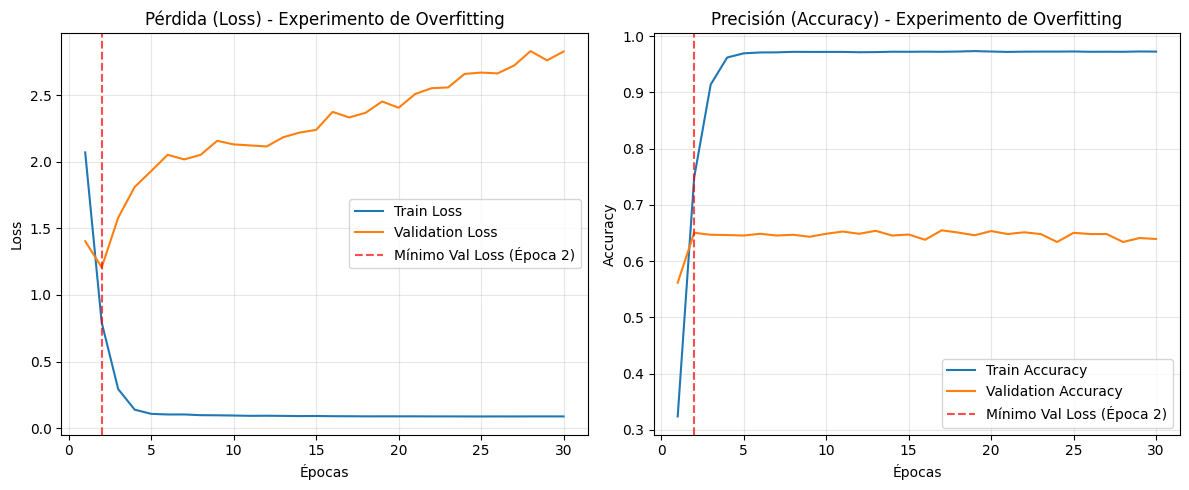

In [ ]:
# Configuración del experimento de Overfitting (usando split train/val limpio sin tocar test)
OVERFIT_MAX_FEATURES = 10000
OVERFIT_HIDDEN_DIMS = [512, 512, 512]
OVERFIT_EPOCHS = 30
BATCH_SIZE_OVERFIT = 64

train_texts_of, _ = preprocessed_cache[(True, "none")]
tr_of_texts, val_of_texts, tr_of_labels, val_of_labels = train_test_split(
    train_texts_of, newsgroups_train.target, test_size=0.2, random_state=SEED, stratify=newsgroups_train.target
)
X_tr_of, X_val_of, _ = vectorize_data(tr_of_texts, val_of_texts, (1, 2), OVERFIT_MAX_FEATURES, min_df=1)

tr_loader_of = DataLoader(to_tensor_dataset(X_tr_of, tr_of_labels), batch_size=BATCH_SIZE_OVERFIT, shuffle=True)
val_loader_of = DataLoader(to_tensor_dataset(X_val_of, val_of_labels), batch_size=BATCH_SIZE_OVERFIT, shuffle=False)

torch.manual_seed(SEED)
model_overfit = DynamicMLP(input_dim=X_tr_of.shape[1], hidden_dims=OVERFIT_HIDDEN_DIMS, num_classes=NUM_CLASSES, activation_name="relu")
print(f"Parámetros del MLP de Overfitting: {count_parameters(model_overfit):,}")
optimizer_overfit = optim.Adam(model_overfit.parameters(), lr=1e-3)

history_overfit = train_mlp_model(model_overfit, tr_loader_of, val_loader_of, optimizer_overfit, epochs=OVERFIT_EPOCHS, run_name="overfit_exp", verbose=False, eval_label="Val")

# Detección numérica exacta del punto de divergencia (mínimo val_loss)
best_val_ep = int(np.argmin(history_overfit["val_loss"])) + 1
print(f"\nPunto de inflexión (mínima Val Loss): Época {best_val_ep}")
print(f"  En Época {best_val_ep:2d} -> train_loss: {history_overfit['train_loss'][best_val_ep-1]:.4f}, val_loss: {history_overfit['val_loss'][best_val_ep-1]:.4f} | "
      f"train_acc: {history_overfit['train_acc'][best_val_ep-1]:.4f}, val_acc: {history_overfit['val_acc'][best_val_ep-1]:.4f}")
print(f"  En Época {OVERFIT_EPOCHS:2d} -> train_loss: {history_overfit['train_loss'][-1]:.4f}, val_loss: {history_overfit['val_loss'][-1]:.4f} | "
      f"train_acc: {history_overfit['train_acc'][-1]:.4f}, val_acc: {history_overfit['val_acc'][-1]:.4f}")

# Gráfico de diagnóstico del Overfitting (rotulado correctamente como Validation)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, OVERFIT_EPOCHS + 1), history_overfit["train_loss"], label="Train Loss")
plt.plot(range(1, OVERFIT_EPOCHS + 1), history_overfit["val_loss"], label="Validation Loss")
plt.axvline(best_val_ep, color="red", linestyle="--", alpha=0.7, label=f"Mínimo Val Loss (Época {best_val_ep})")
plt.title("Pérdida (Loss) - Experimento de Overfitting")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, OVERFIT_EPOCHS + 1), history_overfit["train_acc"], label="Train Accuracy")
plt.plot(range(1, OVERFIT_EPOCHS + 1), history_overfit["val_acc"], label="Validation Accuracy")
plt.axvline(best_val_ep, color="red", linestyle="--", alpha=0.7, label=f"Mínimo Val Loss (Época {best_val_ep})")
plt.title("Precisión (Accuracy) - Experimento de Overfitting")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

In [ ]:
best = study_mlp.best_params

BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_BATCH_SIZE = best["batch_size"]
BEST_ACTIVATION = best["activation"]
BEST_OPT = best["optimizer"]
BEST_LR = best[f"lr_{BEST_OPT}"]

n_layers = best["n_layers"]
BEST_HIDDEN_DIMS = [best[f"n_units_l{i}"] for i in range(n_layers)]

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, _ = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target), batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target), batch_size=BEST_BATCH_SIZE, shuffle=False)

torch.manual_seed(SEED)
model_final = DynamicMLP(
    input_dim=X_train_final.shape[1],
    hidden_dims=BEST_HIDDEN_DIMS,
    num_classes=NUM_CLASSES,
    activation_name=BEST_ACTIVATION
)
mlp_final_params = count_parameters(model_final)
print(f"Arquitectura MLP ganadora: {BEST_HIDDEN_DIMS} ({BEST_ACTIVATION}) | Parámetros entrenables: {mlp_final_params:,}")

if BEST_OPT == "adam":
    optimizer_final = optim.Adam(model_final.parameters(), lr=BEST_LR, betas=(best["adam_beta1"], best["adam_beta2"]))
elif BEST_OPT == "rmsprop":
    optimizer_final = optim.RMSprop(model_final.parameters(), lr=BEST_LR, alpha=best["rmsprop_alpha"], momentum=best["rmsprop_momentum"])
else:
    optimizer_final = optim.SGD(model_final.parameters(), lr=BEST_LR, momentum=best["sgd_momentum"])

print("Entrenando el mejor MLP por 15 épocas...")
history_final = train_mlp_model(model_final, train_loader_final, test_loader_final, optimizer_final, epochs=15, run_name="mlp_final", verbose=True, eval_label="Test")
print(f"Tiempo total entrenamiento final MLP: {history_final['total_time']:.2f}s (promedio {np.mean(history_final['epoch_times']):.2f}s/época)")

Arquitectura MLP ganadora: [512, 512] (leaky_relu) | Parámetros entrenables: 5,393,428
Entrenando el mejor MLP por 15 épocas...
[mlp_final] Epoch  1/15 (12.18s) - train_loss: 2.7501 train_acc: 0.2970 - test_loss: 2.2500 test_acc: 0.4129
[mlp_final] Epoch  2/15 (11.52s) - train_loss: 1.7135 train_acc: 0.5658 - test_loss: 1.5432 test_acc: 0.5584
[mlp_final] Epoch  3/15 (11.41s) - train_loss: 1.1009 train_acc: 0.7063 - test_loss: 1.2645 test_acc: 0.6289
[mlp_final] Epoch  4/15 (10.69s) - train_loss: 0.7736 train_acc: 0.7954 - test_loss: 1.1618 test_acc: 0.6508
[mlp_final] Epoch  5/15 (11.54s) - train_loss: 0.5702 train_acc: 0.8491 - test_loss: 1.1243 test_acc: 0.6701
[mlp_final] Epoch  6/15 (11.48s) - train_loss: 0.4304 train_acc: 0.8845 - test_loss: 1.1441 test_acc: 0.6726
[mlp_final] Epoch  7/15 (11.44s) - train_loss: 0.3304 train_acc: 0.9134 - test_loss: 1.1975 test_acc: 0.6735
[mlp_final] Epoch  8/15 (11.47s) - train_loss: 0.2579 train_acc: 0.9348 - test_loss: 1.2503 test_acc: 0.6710


## 8. Evaluación final


Accuracy Final del MLP en Test: 0.6468

                          precision    recall  f1-score   support

             alt.atheism       0.55      0.44      0.49       319
           comp.graphics       0.64      0.59      0.61       389
 comp.os.ms-windows.misc       0.58      0.59      0.59       394
comp.sys.ibm.pc.hardware       0.57      0.57      0.57       392
   comp.sys.mac.hardware       0.70      0.65      0.68       385
          comp.windows.x       0.76      0.63      0.69       395
            misc.forsale       0.71      0.73      0.72       390
               rec.autos       0.70      0.65      0.67       396
         rec.motorcycles       0.73      0.70      0.72       398
      rec.sport.baseball       0.55      0.86      0.67       397
        rec.sport.hockey       0.91      0.85      0.88       399
               sci.crypt       0.81      0.67      0.73       396
         sci.electronics       0.55      0.60      0.57       393
                 sci.med       0.7

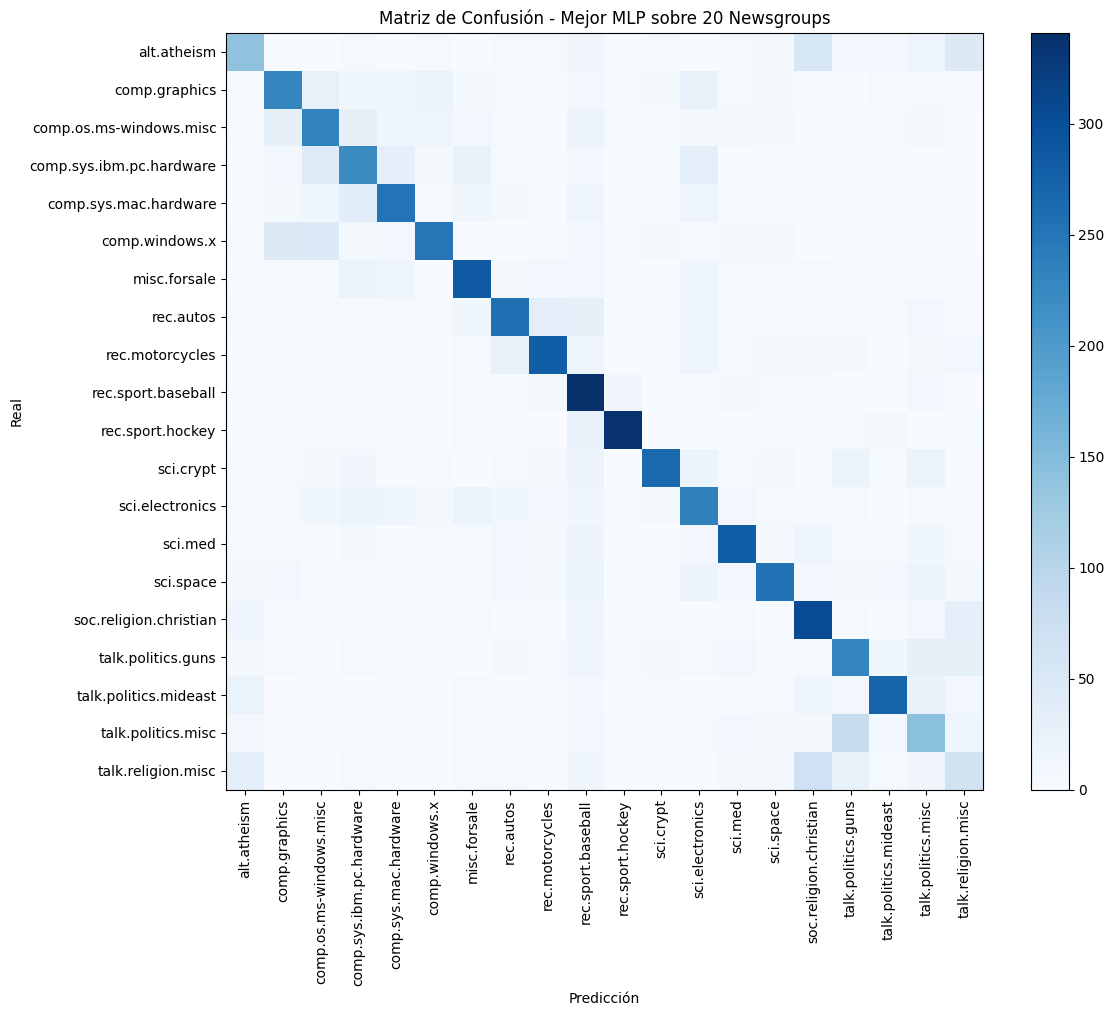

In [ ]:
model_final.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model_final(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"\nAccuracy Final del MLP en Test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Gráfico de Matriz de Confusión
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión - Mejor MLP sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

In [ ]:
# --- Corrida comparativa de Regresión Softmax (TP1) bajo el mismo pipeline ---
def objective_softmax_comp(trial):
    rm_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_t = (1, 1) if ngram == "1gram" else (1, 2)
    max_feat = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    bs = trial.suggest_categorical("batch_size", [32, 64, 128])

    tr_all, _ = preprocessed_cache[(rm_sw, norm)]
    tr_t, va_t, tr_y, va_y = train_test_split(tr_all, newsgroups_train.target, test_size=0.2, random_state=SEED, stratify=newsgroups_train.target)
    X_tr_s, X_va_s, _ = vectorize_data(tr_t, va_t, ngram_t, max_feat, min_df)

    tr_ld = DataLoader(to_tensor_dataset(X_tr_s, tr_y), batch_size=bs, shuffle=True)
    va_ld = DataLoader(to_tensor_dataset(X_va_s, va_y), batch_size=bs, shuffle=False)

    torch.manual_seed(SEED)
    m_sm = SoftmaxRegression(input_dim=X_tr_s.shape[1], num_classes=NUM_CLASSES)
    opt_sm = optim.Adam(m_sm.parameters(), lr=lr)
    hist_sm = train_mlp_model(m_sm, tr_ld, va_ld, opt_sm, epochs=5, verbose=False)
    return hist_sm["val_acc"][-1]

t0_sm_opt = time.time()
study_sm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_sm.optimize(objective_softmax_comp, n_trials=12)
sm_optuna_time = time.time() - t0_sm_opt

# Entrenamiento final de Regresión Softmax (15 épocas sobre train completo)
bsm = study_sm.best_params
sm_tr_txt, sm_te_txt = preprocessed_cache[(bsm["remove_stopwords"], bsm["normalization"])]
X_tr_sm_f, X_te_sm_f, _ = vectorize_data(
    sm_tr_txt, sm_te_txt,
    (1, 1) if bsm["ngram_range"] == "1gram" else (1, 2),
    bsm["max_features"], bsm["min_df"]
)
tr_ld_sm_f = DataLoader(to_tensor_dataset(X_tr_sm_f, newsgroups_train.target), batch_size=bsm["batch_size"], shuffle=True)
te_ld_sm_f = DataLoader(to_tensor_dataset(X_te_sm_f, newsgroups_test.target), batch_size=bsm["batch_size"], shuffle=False)

torch.manual_seed(SEED)
model_sm_final = SoftmaxRegression(input_dim=X_tr_sm_f.shape[1], num_classes=NUM_CLASSES)
sm_final_params = count_parameters(model_sm_final)
opt_sm_final = optim.Adam(model_sm_final.parameters(), lr=bsm["lr"])

history_sm_final = train_mlp_model(model_sm_final, tr_ld_sm_f, te_ld_sm_f, opt_sm_final, epochs=15, run_name="softmax_final", verbose=False, eval_label="Test")
sm_test_acc = history_sm_final["val_acc"][-1]

# Tabla comparativa consolidada con datos reales de esta ejecución
comp_table = pd.DataFrame({
    "Aspecto": [
        "Parámetros entrenables (modelo final)",
        "Tiempo búsqueda Optuna",
        "Tiempo por época (entrenamiento final)",
        "Tiempo total (15 épocas finales)",
        "Mejor Accuracy en Validación (Optuna)",
        "Accuracy en Test Final (época 15)"
    ],
    "Regresión Softmax (Baseline TP1)": [
        f"{sm_final_params:,}",
        f"{sm_optuna_time:.2f} s (12 trials, sin pruning)",
        f"{np.mean(history_sm_final['epoch_times']):.2f} s",
        f"{history_sm_final['total_time']:.2f} s",
        f"{study_sm.best_value:.4f}",
        f"{sm_test_acc:.4f}"
    ],
    "MLP Optimizado (TP2)": [
        f"{mlp_final_params:,}",
        f"{mlp_optuna_time:.2f} s ({N_TRIALS_MLP} trials, con pruning)",
        f"{np.mean(history_final['epoch_times']):.2f} s",
        f"{history_final['total_time']:.2f} s",
        f"{study_mlp.best_value:.4f}",
        f"{test_accuracy:.4f}"
    ]
})
display(comp_table)

[I 2026-11-19 17:16:57,155] A new study created in memory with name: no-name-4aa481e3-7b4a-4977-960e-7d48d6ae4f60
[I 2026-11-19 17:16:59,735] Trial 0 finished with value: 0.6027397260273972 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0026587543983272706, 'batch_size': 128}. Best is trial 0 with value: 0.6027397260273972.
[I 2026-11-19 17:17:09,086] Trial 1 finished with value: 0.6486964206805126 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.016409286730647923, 'batch_size': 128}. Best is trial 1 with value: 0.6486964206805126.
[I 2026-11-19 17:17:15,134] Trial 2 finished with value: 0.7220503756076005 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.010968217207529524, 'batch_size': 128}. Best is trial 2 with value

,Aspecto,Regresión Softmax (Baseline TP1),MLP Optimizado (TP2)
0,Parámetros entrenables (modelo final),"200,020","5,393,428"
1,Tiempo búsqueda Optuna,"98.92 s (12 trials, sin pruning)","717.18 s (24 trials, con pruning)"
2,Tiempo por época (entrenamiento final),1.07 s,11.45 s
3,Tiempo total (15 épocas finales),16.03 s,171.78 s
4,Mejor Accuracy en Validación (Optuna),0.7221,0.7300
5,Accuracy en Test Final (época 15),0.6575,0.6468


# 9. Analisis de Resultados y Comparativa TP1 y TP2:

### 9.1 Impacto de las Variaciones de Arquitectura, Activaciones y Optimizadores en el MLP

La búsqueda bayesiana (TPE) con Optuna evaluó **24 trials** de hasta 8 épocas sobre la partición estratificada de entrenamiento/validación (80/20), con un tiempo total de **717.18 segundos** (CPU). La configuración ganadora (**Trial 21**) alcanzó una precisión de validación de **0.7300** con **5,393,428 parámetros entrenables** y los siguientes hiperparámetros:
* **Preprocesamiento y vectorización:** `remove_stopwords = False`, `normalization = "stem"`, `ngram_range = "1gram"` `(1, 1)`, `max_features = 10000`, `min_df = 2`, `batch_size = 128`.
* **Arquitectura:** **2 capas ocultas** de `[512, 512]` neuronas con activación `leaky_relu`.
* **Optimizador:** `Adam` con `lr = 3.86e-4`, $\beta_1 = 0.8540$ y $\beta_2 = 0.9294$.

Del análisis agregado de los **17 trials completados** (y los 7 podados) surgen las siguientes conclusiones respaldadas empíricamente[cite: 4, 5]:

1. **Funciones de Activación (y aclaración teórica sobre GELU):**
   * En los trials completados, `leaky_relu` alcanzó el mejor pico de validación (**0.7300** en el Trial 21, media **0.5742** en 3 trials), seguida muy de cerca por `relu` (máximo **0.7203** en el Trial 18, media **0.6225** en 5 trials) y `tanh` (máximo **0.7167** en el Trial 19, con la media más alta de **0.6615** a lo largo de 8 trials)[cite: 4, 5]. `gelu` solo completó 1 trial de referencia (**0.6412**), ya que el muestreador TPE concentró las evaluaciones posteriores en `tanh`, `relu` y `leaky_relu`[cite: 4].
   * *Nota teórica:* **GELU** (*Gaussian Error Linear Unit*, $\text{GELU}(x) = x\,\Phi(x)$) no aplica una pendiente lineal pequeña para valores negativos como `LeakyReLU`, sino que pondera suavemente la entrada por la función de distribución acumulada normal estándar $\Phi(x)$, generando una transición diferenciable alrededor de cero que tiende a cero para valores muy negativos.

2. **Profundidad y Capacidad (Capas Ocultas):**
   * Las arquitecturas de **2 capas ocultas** obtuvieron el mejor desempeño global (media **0.6620** y máximo **0.7300** en 9 trials completados), superando tanto a las redes de **1 capa** (media **0.6338**, máximo **0.6571** en 5 trials) como a las de **3 capas** (media **0.5472**, máximo **0.6425** en 3 trials)[cite: 5]. Una sola capa limita la capacidad de combinar términos en representaciones latentes de segundo orden, mientras que 3 capas sin regularización degradan la optimización y aceleran el sobreajuste.

3. **Optimizadores y Parámetros de Momento:**
   * **Adam** fue el optimizador más efectivo (11 trials completados, media **0.6493**, máximo **0.7300**), seguido por **RMSprop** (5 trials completados, media **0.6464**, máximo **0.6995**)[cite: 4]. Ambos métodos adaptativos escalan el paso por coordenada mediante promedios móviles de gradientes al cuadrado, lo cual resulta clave frente a vectores TF-IDF dispersos donde distintas palabras tienen frecuencias muy desiguales.
   * En el modelo ganador, Adam seleccionó una tasa de aprendizaje conservadora (`lr = 3.86e-4`) adecuada para estabilizar una red de 5.39 millones de parámetros, junto con $\beta_1 = 0.854$ y $\beta_2 = 0.929$ (menores a los valores por defecto `0.9` y `0.999`), permitiendo que las estimaciones de momento se adapten más rápido a los cambios de gradiente entre mini-batches[cite: 5].
   * **SGD con Momentum** completó 1 trial (**0.3933**, `9.55 s`)[cite: 4] y sus restantes intentos fueron podados tempranamente por `MedianPruner`: al carecer de adaptación por parámetro, en 8 épocas converge mucho más lento que Adam/RMSprop sobre entradas dispersas de 10.000 dimensiones.

4. **Efectividad del Pruning y Varianza Estadística:**
   * El uso de `MedianPruner` (`n_startup_trials=6`, `n_warmup_steps=4`) podó **7 de los 24 trials**, ejecutando **171 de las 192 épocas máximas** y logrando un **ahorro efectivo de 21 épocas (10.9%, ~88.0 segundos estimados)** sin descartar configuraciones prometedoras.
   * *Limitación muestral:* dado que la partición de validación contiene ~2.263 documentos (20% de `train`) y se evaluó una única semilla (`SEED = 42`), el error estándar de muestreo ronda $\pm 0.9$ puntos porcentuales; por ello, las diferencias entre los primeros trials (**0.7300** vs. **0.7203** vs. **0.7167**) caen dentro del margen de ruido estadístico[cite: 5].

---

### 9.2 Diagnóstico del Experimento de Overfitting

Para analizar el comportamiento en régimen de sobreajuste de manera metodológicamente limpia, se entrenó un MLP de alta capacidad (**3 capas ocultas de `[512, 512, 512]` neuronas**, ReLU, `max_features = 10000` con bigramas `(1, 2)`, **5,656,084 parámetros**) durante **30 épocas** sin regularización sobre el split interno de entrenamiento/validación (80/20, sin tocar el conjunto de test):

* **Punto exacto de inflexión (Época 2):** la pérdida de validación (`val_loss`) alcanzó su mínimo en la **época 2** con `val_loss = 1.2063` y `val_acc = 0.6505` (mientras que en entrenamiento `train_loss = 0.7930` y `train_acc = 0.7490`).
* **Divergencia hasta la Época 30:** a partir de la época 3, ambas curvas se separan drásticamente. Al llegar a la **época 30**, `train_loss` cae hasta **0.0877** (`train_acc = 0.9726`), mientras que `val_loss` se dispara más del doble hasta **2.8272** y `val_acc` retrocede a **0.6394**.
* **Causa del fenómeno:** con 5.65 millones de parámetros frente a 9.051 documentos de entrenamiento, la red memoriza combinaciones específicas de n-gramas del conjunto de entrenamiento en lugar de extraer patrones generalizables. Esto evidencia la necesidad de incorporar técnicas de regularización (como *Weight Decay* $L_2$, *Dropout* o *Early Stopping*) en arquitecturas MLP sobre texto.

---

### 9.3 Comparativa Real: Regresión Softmax (TP1) vs. MLP Optimizado (TP2)

Para garantizar una comparación justa bajo exactamente el mismo preprocesamiento, partición de datos y entorno de cómputo, se ejecutó también la optimización con Optuna (12 trials) y el entrenamiento final de 15 épocas de **Regresión Softmax** dentro de este mismo notebook[cite: 7]:

| Aspecto | Regresión Softmax (Baseline TP1) | MLP Optimizado (TP2) |
| :--- | :--- | :--- |
| **Arquitectura** | 1 capa lineal (`10000 -> 20`) | 2 capas ocultas `[512, 512]` + `LeakyReLU`[cite: 5] |
| **Parámetros entrenables (modelo final)** | 200,020[cite: 7] | 5,393,428 (~27 veces más)[cite: 7] |
| **Búsqueda de hiperparámetros** | Optuna TPE (12 trials, `98.92 s`)[cite: 7] | Optuna TPE + Pruning (24 trials, `717.18 s`)[cite: 7] |
| **Tiempo por época (entrenamiento final)** | 1.07 s[cite: 7] | 11.45 s (~10.7x más lento)[cite: 7] |
| **Tiempo total (15 épocas finales)** | 16.03 s[cite: 7] | 171.78 s[cite: 7] |
| **Mejor Accuracy en Validación (Optuna)** | 0.7221[cite: 7] | **0.7300** (+0.79 pts)[cite: 7] |
| **Pico de Accuracy en Test (durante entrenamiento)** | — | **0.6735** (en Época 7, `test_loss = 1.1975`) |
| **Accuracy en Test Final (Época 15)** | **0.6575**[cite: 7] | 0.6468 (`test_loss = 1.9073`)[cite: 7] |

#### Conclusiones de la Comparativa
1. **Capacidad representacional vs. sobreajuste sin regularización:** en validación (8 épocas), el MLP supera a Regresión Softmax (**0.7300** vs. **0.7221**) gracias a su capacidad para modelar combinaciones no lineales de términos[cite: 7]. En el entrenamiento final de 15 épocas sobre todo `train`, el MLP alcanza su mejor desempeño en test en la **época 7 (`0.6735`)** (con mínima `test_loss = 1.1243` en la época 5), pero al continuar entrenando sin *Early Stopping* ni regularización hasta la época 15 (`train_acc = 0.9712`), sobreajusta y termina en **0.6468** frente al **0.6575** del modelo lineal[cite: 7].
2. **Compromiso costo-beneficio (*trade-off*):** sobre representaciones dispersas TF-IDF de alta dimensión, Regresión Softmax ofrece una línea base sumamente competitiva entrenando **10.7 veces más rápido por época** (`1.07 s` vs. `11.45 s`) y con **27 veces menos parámetros** (`200,020` vs. `5,393,428`)[cite: 7]. El potencial extra del MLP requiere necesariamente técnicas de regularización para capitalizarse en test sin degradar la generalización (aspecto abordado en el TP3).

---

### Declaración de uso de IA
Se utilizó asistencia de inteligencia artificial (Gemini) como herramienta de apoyo para la estructuración de las explicaciones teóricas, la revisión de redacción y el diseño del código de instrumentación de tiempos, conteo de parámetros y comparación entre modelos.